<div align="center">

# 🌍 BE AN EARTH SYSTEM TREND DETECTIVE

### NASA SPACE APPS CHALLENGE 2026

**Team Name: BE AN EARTH TREND DETECTIVE**

---

### 📡 EARTH OBSERVATION • CLIMATE ANALYTICS • STATISTICAL RESEARCH

</div>

---

## A. Project Overview

Earth's climate system is constantly evolving. Understanding long-term environmental patterns is essential for identifying climate variability and potential changes in Earth's systems.

This project investigates historical precipitation patterns across **India** using satellite-based observations from NASA's **Global Precipitation Measurement (GPM) – IMERG Final V07** dataset.

The project uses Python-based data analysis, scientific visualization, and statistical methods to investigate precipitation variability and detect possible long-term trends.

In [1]:
from IPython.display import display, HTML

display(HTML('<center><img src="Indian_Subcontinent.jpg" width="500"></center>'))

## B. Research Objective

The primary objective is to analyse precipitation patterns across India over a 20-year study period (October 2005 – September 2025).

The research aims to:

- Examine monthly and annual precipitation variability.
- Identify seasonal precipitation patterns.
- Investigate possible long-term increasing or decreasing trends.
- Estimate the magnitude and statistical significance of detected trends.
- Present findings through clear, reproducible visualizations.


## C. Study Area and Dataset

| Parameter | Description |
|:---|:---|
| Study Region | India |
| Data Source | NASA Giovanni |
| Satellite Product | GPM IMERG Final V07 |
| Variable | Precipitation Rate |
| Temporal Resolution | Monthly |
| Study Period | October 2005 – September 2025 |
| Geographic Coverage | India |
| Measurement Unit | mm/hr |

## D. Loading and Preparing the Dataset

The NASA Giovanni CSV file contains metadata followed by the monthly precipitation observations.

We skip the metadata rows, assign clear column names, and prepare the dataset for analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
file_path = "india_monthly_precipitation.csv"
data = pd.read_csv(file_path, skiprows=7)
data.head()

,time,mean_GPM_3IMERGM_07_precipitation
0,2005-10-01 00:00:00,0.162110
1,2005-11-01 00:00:00,0.039237
2,2005-12-01 00:00:00,0.016804
3,2006-01-01 00:00:00,0.011609
4,2006-02-01 00:00:00,0.016165


In [3]:
data.columns = ["date", "precipitation"]

data["date"] = pd.to_datetime(data["date"])
data["precipitation"] = pd.to_numeric(data["precipitation"])

data.head()

,date,precipitation
0,2005-10-01,0.162110
1,2005-11-01,0.039237
2,2005-12-01,0.016804
3,2006-01-01,0.011609
4,2006-02-01,0.016165


In [4]:
df = data.copy()
df.head(10)

,date,precipitation
0,2005-10-01,0.162110
1,2005-11-01,0.039237
2,2005-12-01,0.016804
3,2006-01-01,0.011609
4,2006-02-01,0.016165
5,2006-03-01,0.051601
6,2006-04-01,0.050378
7,2006-05-01,0.135122
8,2006-06-01,0.221772
9,2006-07-01,0.398609


In [5]:
df.tail(10)

,date,precipitation
230,2024-12-01,0.034011
231,2025-01-01,0.007975
232,2025-02-01,0.020852
233,2025-03-01,0.021277
234,2025-04-01,0.060075
235,2025-05-01,0.217744
236,2025-06-01,0.291071
237,2025-07-01,0.436747
238,2025-08-01,0.417546
239,2025-09-01,0.318060


In [6]:
df.shape

(240, 2)

## E. Research Methodology

The project follows a structured scientific workflow:

1. Data acquisition and initial inspection.
2. Data quality assessment and preprocessing.
3. Exploratory Data Analysis (EDA).
4. Monthly, annual, and seasonal pattern analysis.
5. Statistical trend detection.
6. Interpretation of results and scientific conclusions.

In [7]:
### Dataset information
df.info()
## Statistical summary
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           240 non-null    datetime64[us]
 1   precipitation  240 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.9 KB


,date,precipitation
count,240,240.000000
mean,2015-09-16 03:30:00,0.139780
min,2005-10-01 00:00:00,0.006252
25%,2010-09-23 12:00:00,0.025669
50%,2015-09-16 00:00:00,0.070643
75%,2020-09-08 12:00:00,0.262554
max,2025-09-01 00:00:00,0.460262
std,NaN,0.140074


## F. Data Quality Assessment

Before conducting statistical analysis, we check for missing values, duplicate records, and invalid precipitation values to ensure data reliability.

In [8]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNegative precipitation values:", (df["precipitation"] < 0).sum())
print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("Total observations:", len(df))

Missing values:
 date             0
precipitation    0
dtype: int64

Duplicate rows: 0

Negative precipitation values: 0

Date range: 2005-10-01 00:00:00 to 2025-09-01 00:00:00
Total observations: 240


### Observations

The initial data quality assessment indicates that the dataset is complete and structurally consistent.

- **Completeness:** No missing values were detected in either the date or precipitation column.
- **Uniqueness:** No duplicate records were identified.
- **Physical Validity:** No negative precipitation values were found.
- **Temporal Coverage:** The dataset contains 240 monthly observations spanning October 2005 to September 2025.
- **Data Readiness:** All observations are available for further exploratory analysis.

**Conclusion:** The dataset passed the initial data quality checks and is suitable for proceeding with exploratory data analysis (EDA). These checks establish data consistency but do not independently verify the accuracy of the satellite measurements.

## Exploratory Data Analysis

### 1. Monthly Precipitation Time Series Analysis

This section visualizes monthly precipitation-rate variations across India over the 20-year study period (October 2005–September 2025).

The time-series plot helps examine temporal variability, recurring fluctuations, and potential long-term patterns in precipitation.

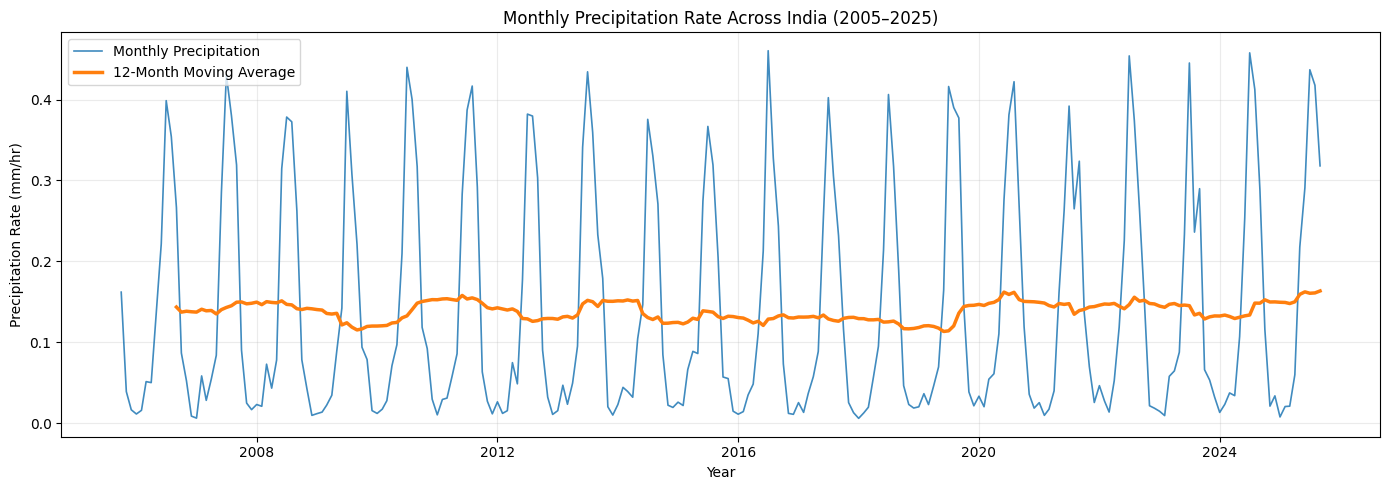

In [9]:
df["12_month_avg"] = df["precipitation"].rolling(window=12).mean()

plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["precipitation"],
         alpha=0.85, linewidth=1.2, label="Monthly Precipitation")

plt.plot(df["date"], df["12_month_avg"],
         linewidth=2.5, label="12-Month Moving Average")

plt.title("Monthly Precipitation Rate Across India (2005–2025)")
plt.xlabel("Year")
plt.ylabel("Precipitation Rate (mm/hr)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

# High-resolution image save (300 DPI per user preference)
plt.savefig("precipitation_trend_highres.png", dpi=300, bbox_inches='tight')
plt.show()

### Observations and Interpretation

The monthly precipitation time series reveals considerable temporal variability across India during the study period (October 2005–September 2025).

**Key Findings:**

1. **Seasonal Variability:** The monthly observations exhibit recurring sharp peaks and low precipitation values, indicating a strong seasonal precipitation pattern.

2. **Smoothed Trend:** The 12-month moving average fluctuates approximately between 0.115 and 0.16 mm/hr, highlighting variations in the longer-term precipitation pattern.

3. **Period-to-Period Changes:** The moving average shows periods of decline, recovery, and relative stability rather than a consistently increasing or decreasing pattern.

4. **Recent Variation:** The moving average shows an increase toward the end of the study period. However, this visual pattern alone does not establish a statistically significant trend.

**Preliminary Conclusion:**

The visualization indicates substantial seasonal variability and fluctuations in India's spatially averaged precipitation rate over the 20-year study period. Further statistical analysis is required to determine the direction, magnitude, and significance of any long-term trend.

### 2. Monthly Seasonal Pattern Analysis

This analysis examines the average precipitation rate for each calendar month across the 20-year study period.

It helps identify seasonal patterns and months with relatively higher or lower precipitation across India.

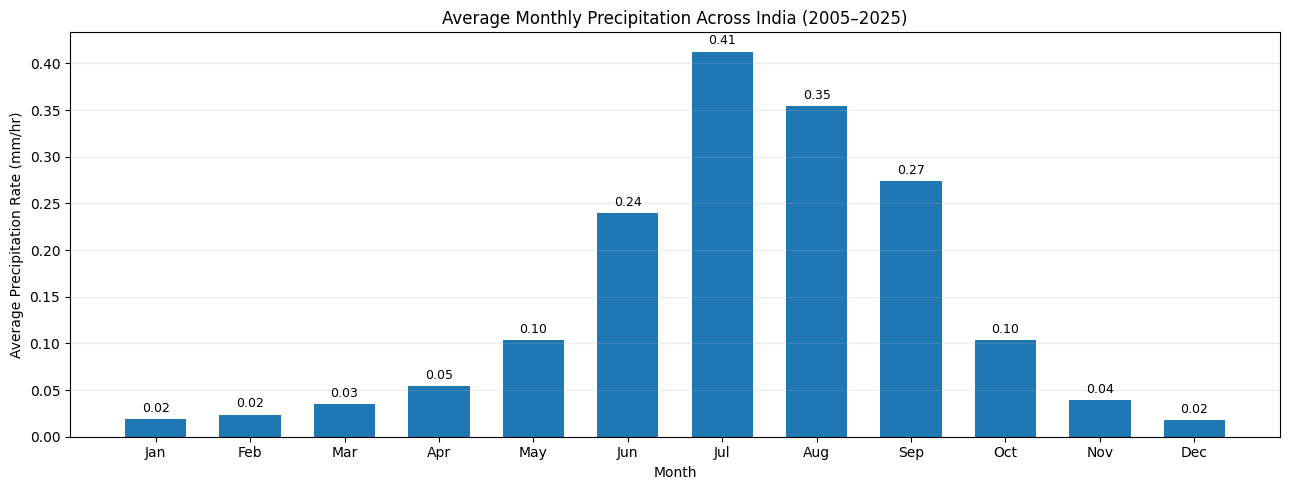

In [10]:
monthly_avg = df.groupby(df["date"].dt.month)["precipitation"].mean()

plt.figure(figsize=(13, 5))

bars = plt.bar(monthly_avg.index, monthly_avg.values, width=0.65)

plt.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

plt.xticks(range(1, 13),
           ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.title("Average Monthly Precipitation Across India (2005–2025)")
plt.xlabel("Month")
plt.ylabel("Average Precipitation Rate (mm/hr)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Observations and Interpretation

The monthly analysis reveals a clear seasonal pattern in India's precipitation.

- July records the highest average precipitation rate, followed by August.
- September also shows relatively high precipitation.
- Precipitation increases substantially from June and remains high during the monsoon months.
- December, January, and February show the lowest average precipitation rates.

**Conclusion:**

The results indicate a strong seasonal precipitation cycle across India, with the highest precipitation during the summer monsoon period and considerably lower precipitation during winter.

This seasonal pattern highlights the importance of monsoon rainfall in India's precipitation distribution.

### 3. Annual Precipitation Trend Analysis

This analysis examines year-wise average precipitation rates to understand how precipitation patterns have changed over the study period.

Only complete calendar years with all 12 monthly observations are included to ensure a fair annual comparison.

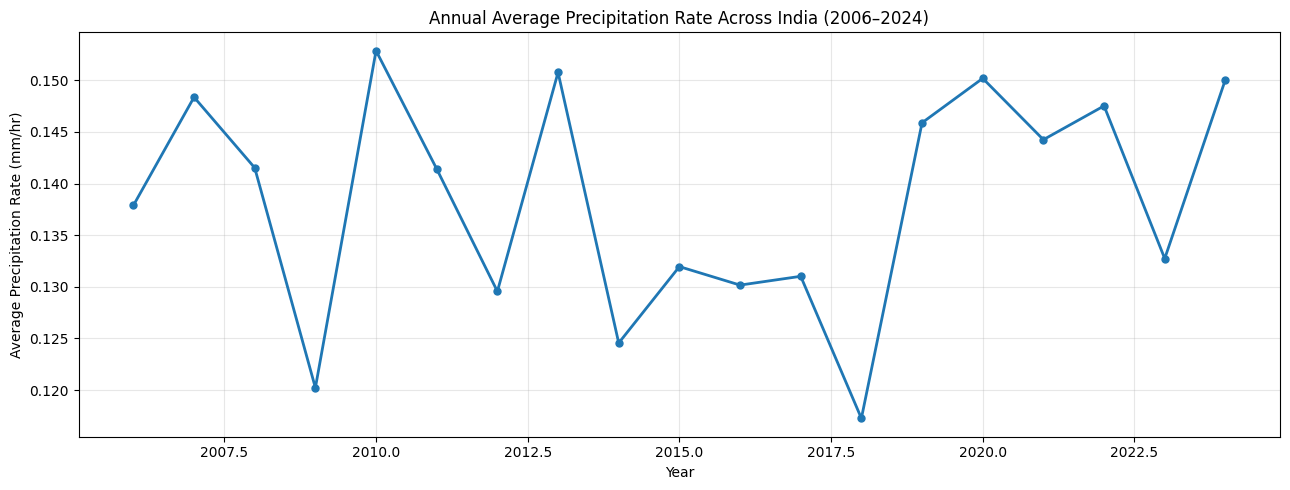

In [11]:
annual_avg = df.groupby(df["date"].dt.year)["precipitation"].agg(["mean", "count"])
annual_avg = annual_avg[annual_avg["count"] == 12]

plt.figure(figsize=(13, 5))

plt.plot(annual_avg.index, annual_avg["mean"],
         marker="o", linewidth=2, markersize=5)

plt.title("Annual Average Precipitation Rate Across India (2006–2024)")
plt.xlabel("Year")
plt.ylabel("Average Precipitation Rate (mm/hr)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observations and Interpretation

The annual precipitation analysis reveals considerable year-to-year variability across India during 2006–2024.

- 2010 recorded the highest annual average precipitation rate.
- 2018 recorded the lowest annual average precipitation rate.
- Higher annual averages were observed during 2019–2022.
- A decline occurred in 2023, followed by an increase in 2024.

**Conclusion:**

Annual precipitation shows noticeable fluctuations rather than a consistent increasing or decreasing pattern. Statistical trend analysis is required to determine whether these changes represent a significant long-term trend.

### 4. Precipitation Anomaly Analysis

This analysis identifies deviations in monthly precipitation from their long-term calendar-month averages.

Positive anomalies indicate higher-than-usual precipitation, while negative anomalies indicate lower-than-usual precipitation.

This helps identify unusually wet and dry periods across the study period.

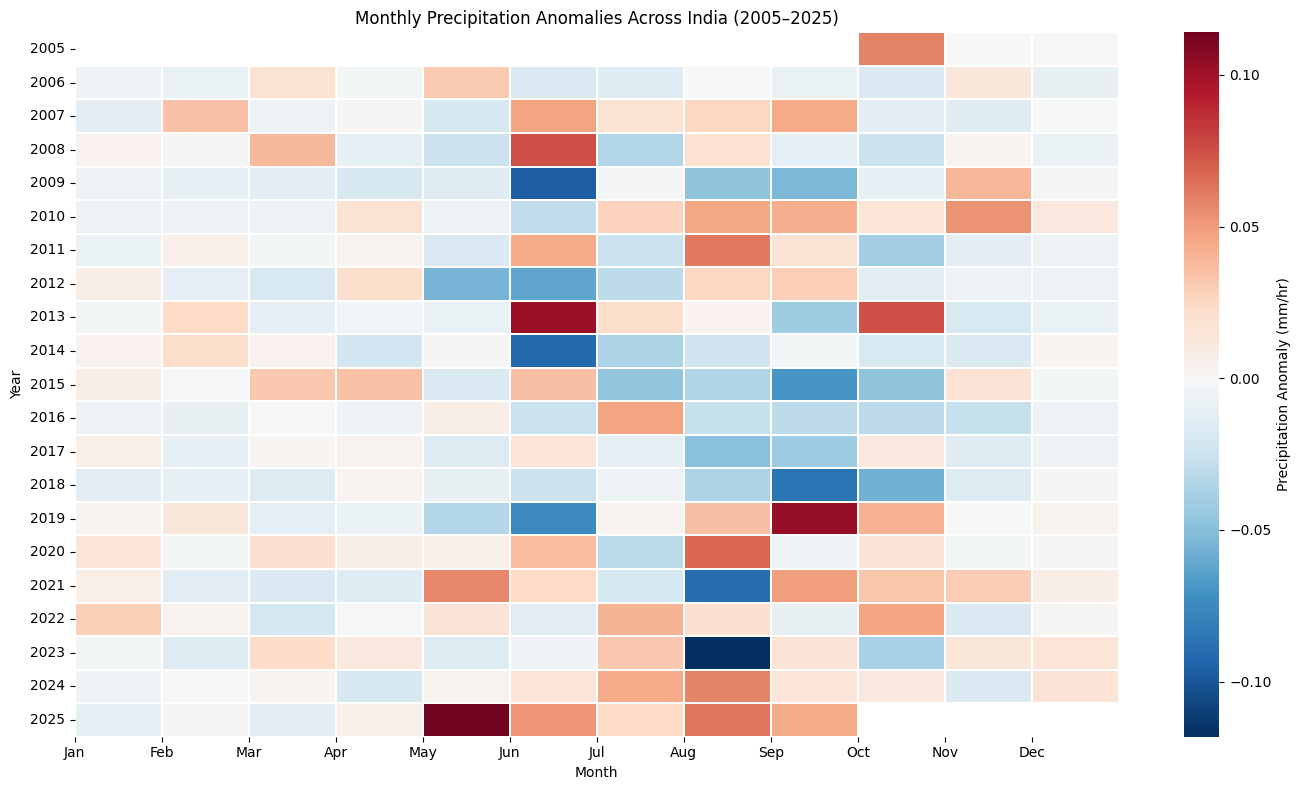

In [12]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

monthly_normal = df.groupby("month")["precipitation"].transform("mean")
df["anomaly"] = df["precipitation"] - monthly_normal

heatmap_data = df.pivot(
    index="year", columns="month", values="anomaly")

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    linewidths=0.3,
    cbar_kws={"label": "Precipitation Anomaly (mm/hr)"})

plt.title("Monthly Precipitation Anomalies Across India (2005–2025)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.tight_layout()
plt.show()

### Observations and Interpretation

The precipitation anomaly heatmap reveals substantial variations in monthly precipitation compared with the corresponding long-term monthly averages.

**Key Observations:**

- Both positive and negative anomalies occur throughout the study period.
- Monsoon months (June–September) exhibit considerable year-to-year variability.
- September 2019 shows a notably positive precipitation anomaly.
- August 2023 shows a notably negative precipitation anomaly.
- June 2013 also exhibits a strong positive anomaly.

**Conclusion:**

The heatmap highlights considerable temporal variability in India's precipitation patterns. Certain months experienced unusually high or low precipitation compared with their respective historical monthly averages.

These anomalies indicate deviations from normal conditions, but do not independently establish a long-term increasing or decreasing trend.

### 5. Seasonal Precipitation Distribution

This analysis compares the distribution of monthly precipitation rates across all calendar months during the study period.

A box plot helps identify the median, variability, spread, and potential outliers for each month.

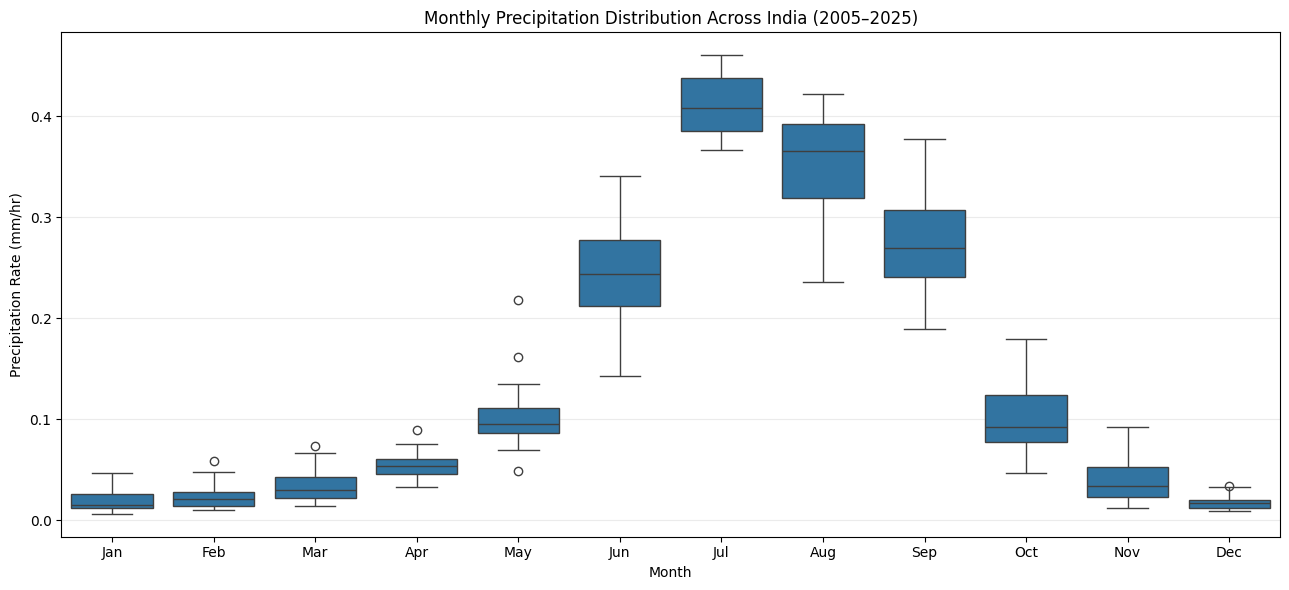

In [13]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x=df["date"].dt.month,
            y="precipitation")

plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.title("Monthly Precipitation Distribution Across India (2005–2025)")
plt.xlabel("Month")
plt.ylabel("Precipitation Rate (mm/hr)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Observations and Interpretation

The monthly precipitation distribution reveals a strong seasonal pattern across India.

**Key Observations:**

- July exhibits the highest median precipitation rate, followed by August.
- June to September show substantially higher precipitation levels.
- December, January, and February record the lowest median precipitation rates.
- May contains several potential outliers, indicating unusual monthly precipitation values.
- The spread of observations varies across months, reflecting differences in precipitation variability.

**Conclusion:**

The box plot confirms a pronounced seasonal precipitation pattern, with higher precipitation during the monsoon season and lower precipitation during winter. It also highlights month-to-month differences in variability and potential extreme observations.

### 6 Annual Precipitation Anomaly Analysis

This analysis compares each year's average precipitation rate with the long-term annual average to identify relatively wetter and drier years.

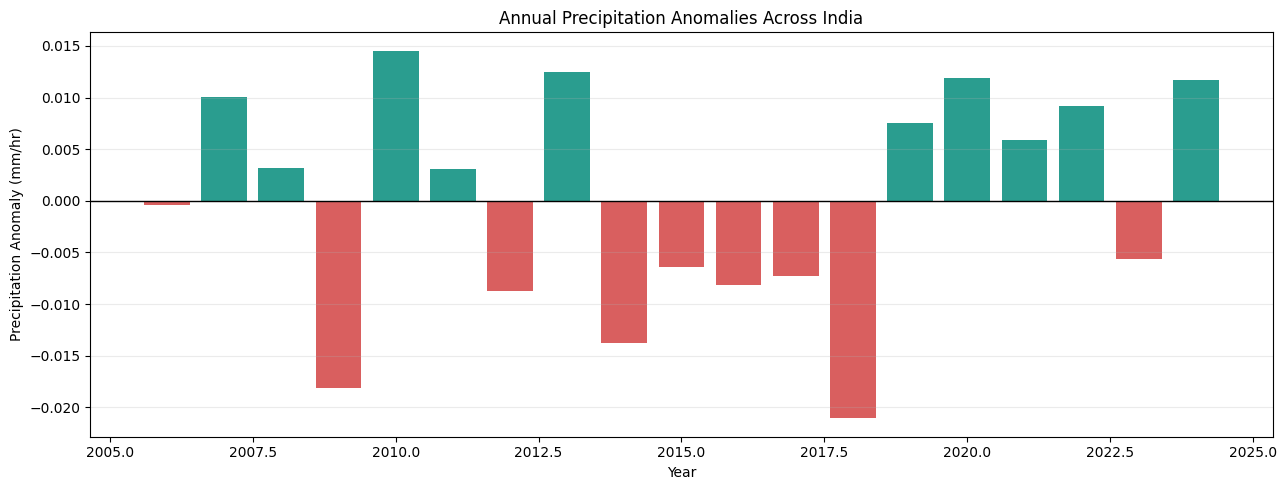

In [14]:
annual = df.groupby(df["date"].dt.year)["precipitation"].agg(["mean", "count"])
annual = annual[annual["count"] == 12]

annual["anomaly"] = annual["mean"] - annual["mean"].mean()

plt.figure(figsize=(13, 5))

colors = ["#D95F5F" if x < 0 else "#2A9D8F" for x in annual["anomaly"]]

plt.bar(annual.index, annual["anomaly"], color=colors)
plt.axhline(0, color="black", linewidth=1)

plt.title("Annual Precipitation Anomalies Across India")
plt.xlabel("Year")
plt.ylabel("Precipitation Anomaly (mm/hr)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Observations and Interpretation

The annual precipitation anomaly analysis highlights substantial year-to-year variations relative to the long-term annual average.

**Key Findings:**

- 2010 recorded the highest positive annual anomaly.
- 2018 recorded the strongest negative annual anomaly.
- Several years between 2014 and 2018 showed below-average precipitation.
- The period 2019–2022 showed consecutive positive annual anomalies.
- 2023 experienced a negative anomaly, followed by a positive anomaly in 2024.

**Conclusion:**

The analysis reveals alternating wetter and drier years across India. These variations highlight the importance of statistical testing before determining whether a significant long-term precipitation trend exists.

## G. Statistical Trend Analysis

This section investigates long-term precipitation trends across India using statistical methods. The objective is to determine the direction, magnitude, and statistical significance of observed precipitation changes.

The analysis includes Linear Regression, confidence intervals, the Mann-Kendall trend test, and Sen's Slope estimation.

### 7. Linear Regression Analysis

Linear Regression is used to estimate the long-term direction and rate of change in India's monthly precipitation over the study period (2005–2025).

The analysis estimates the precipitation trend per year, evaluates the model's explanatory power (R²), and tests statistical significance using the p-value.

In [15]:
from scipy.stats import linregress

x = (df["date"] - df["date"].min()).dt.days / 365.25
y = df["precipitation"]

regression = linregress(x, y)

slope = regression.slope
intercept = regression.intercept
p_value = regression.pvalue
r_squared = regression.rvalue ** 2

print("LINEAR REGRESSION RESULTS")
print("-" * 35)
print(f"Trend rate : {slope:.6f} mm/hr/year")
print(f"P-value    : {p_value:.4f}")
print(f"R-squared  : {r_squared:.4f}")
print(f"Direction  : {'Increasing' if slope > 0 else 'Decreasing' if slope < 0 else 'No change'}")
print(f"Significant: {'Yes' if p_value < 0.05 else 'No'}")

LINEAR REGRESSION RESULTS
-----------------------------------
Trend rate : 0.001348 mm/hr/year
P-value    : 0.3904
R-squared  : 0.0031
Direction  : Increasing
Significant: No


### Observations and Interpretation

- Linear Regression indicates a slight positive precipitation trend.
- The estimated trend rate is +0.001348 mm/hr per year.
- The p-value (0.3904) exceeds the 0.05 significance threshold.
- The R² value (0.0031) indicates that the linear model explains only 0.31% of the observed variation.

**Conclusion:**

Although the estimated trend is slightly increasing, it is not statistically significant. Therefore, the analysis does not establish a significant long-term linear change in India's area-averaged precipitation.

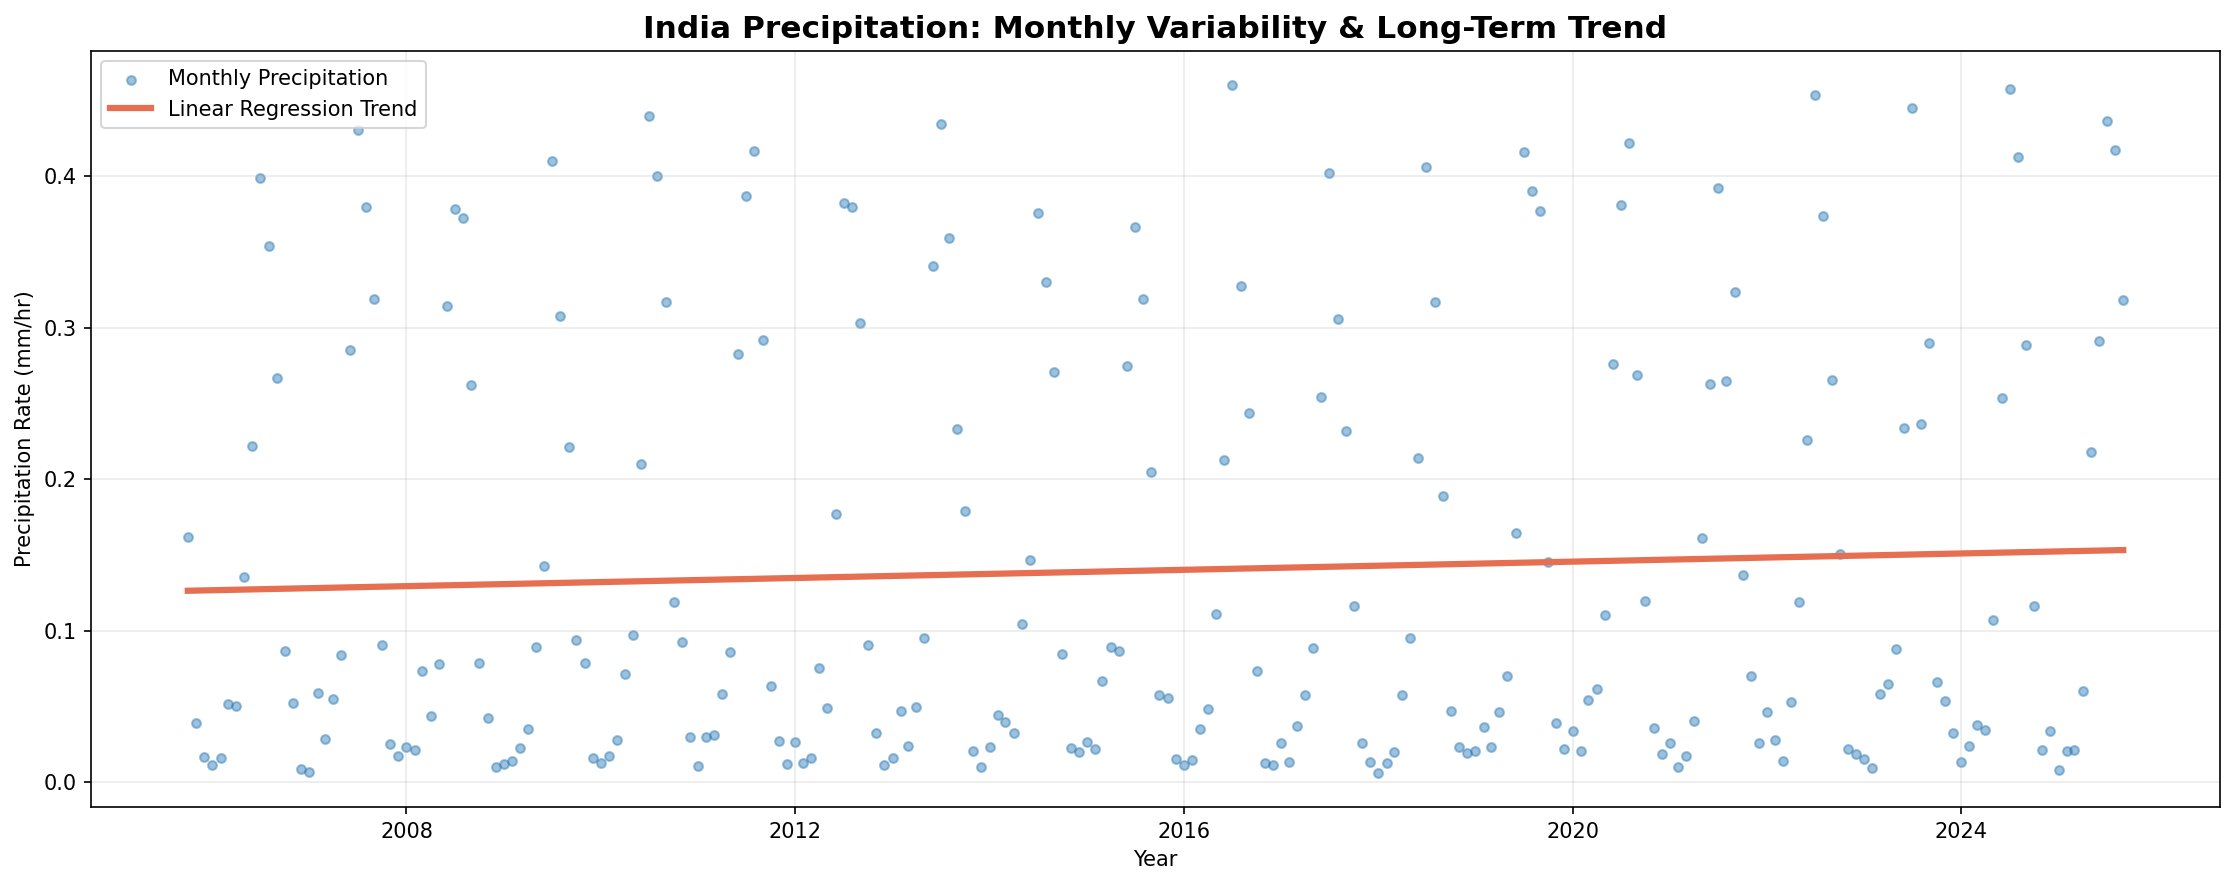

In [16]:
import seaborn as sns

trend = intercept + slope * x

plt.figure(figsize=(15, 6), dpi=150)

plt.scatter(df["date"], y, s=18, alpha=0.45,
            color="#2878B5", label="Monthly Precipitation")

plt.plot(df["date"], trend, color="#E76F51",
         linewidth=3, label="Linear Regression Trend")

plt.title("India Precipitation: Monthly Variability & Long-Term Trend",
          fontsize=15, fontweight="bold")

plt.xlabel("Year")
plt.ylabel("Precipitation Rate (mm/hr)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Graph Observations

- Monthly precipitation shows significant fluctuations throughout 2005–2025.
- Several months record peaks close to 0.45 mm/hr.
- The linear regression line indicates a slight increasing trend.
- However, monthly variability is much higher than the overall long-term change.
- The trend is not statistically significant (p = 0.3904).

**Conclusion:** Precipitation shows a slight positive trend, but there is insufficient statistical evidence to confirm a significant long-term increase.

### 8. Regression Trend Visualization with 95% Confidence Interval
This visualization presents the estimated long-term precipitation trend along with its 95% confidence interval to illustrate the uncertainty around the regression estimate.

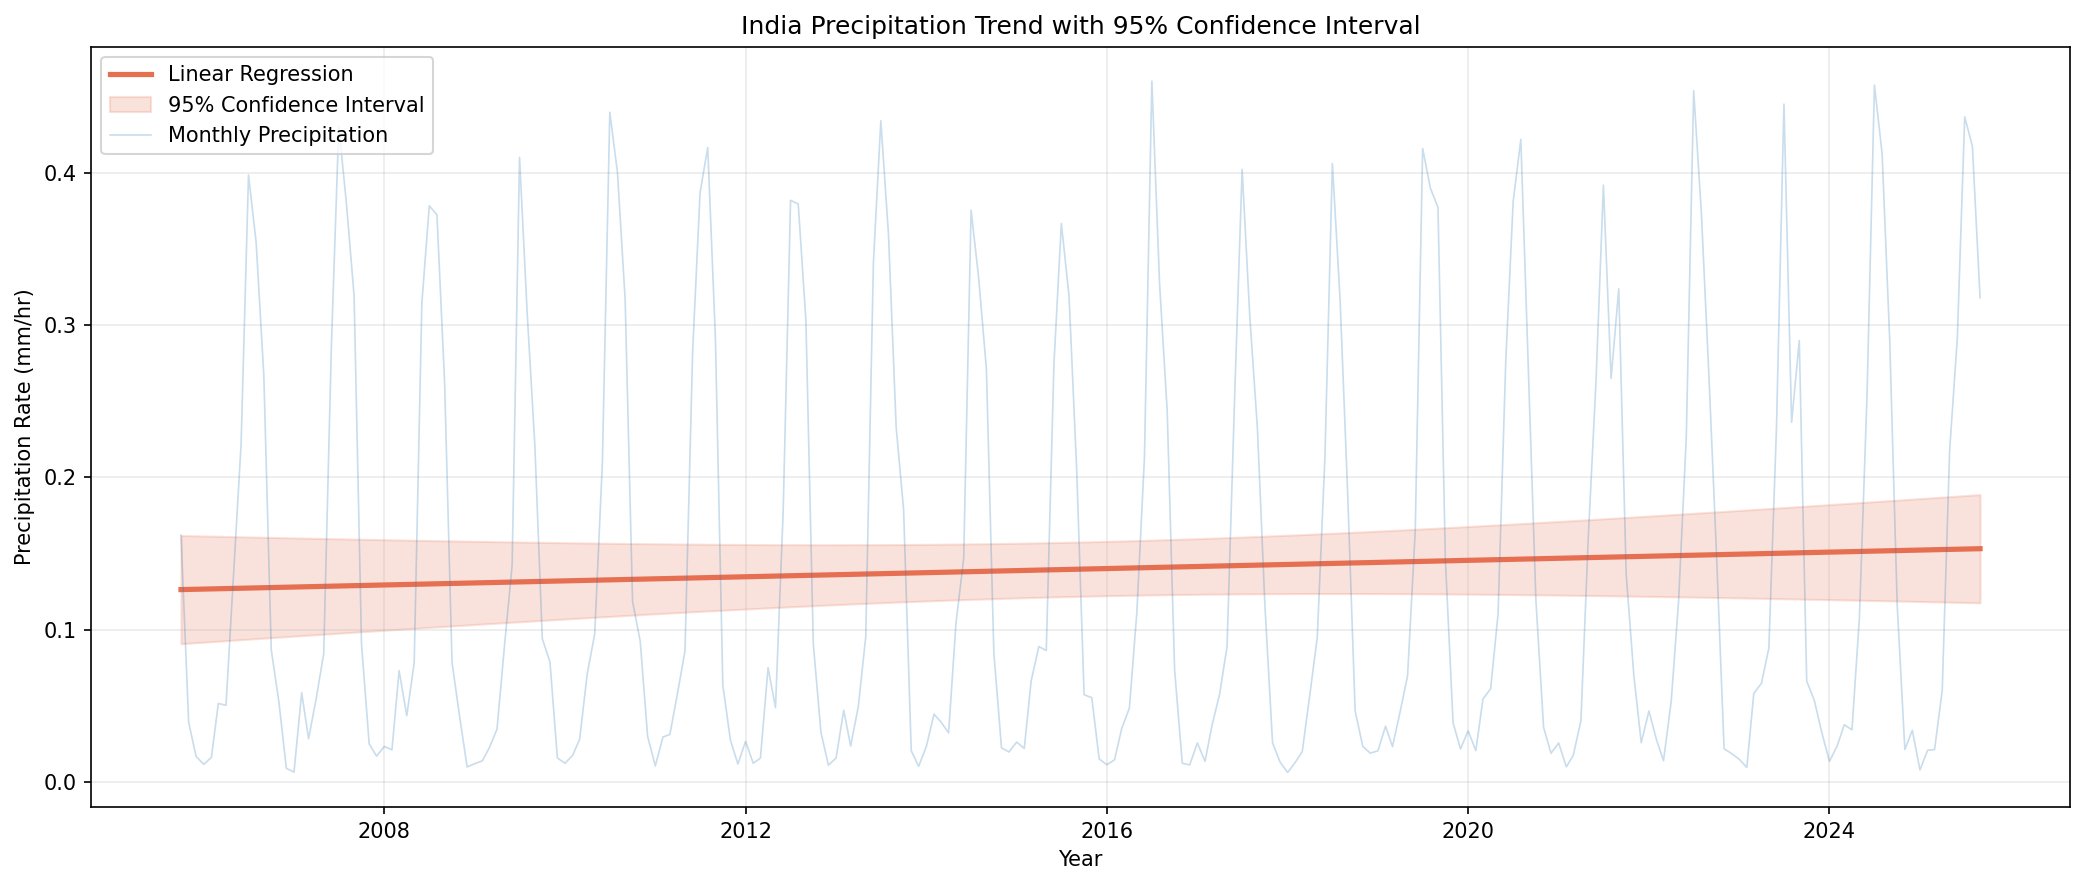

In [17]:
from scipy.stats import t

n = len(x)
x_mean = x.mean()
Sxx = ((x - x_mean) ** 2).sum()

y_pred = intercept + slope * x
residuals = y - y_pred

se = np.sqrt((residuals**2).sum() / (n - 2) *
             (1/n + (x - x_mean)**2 / Sxx))

margin = t.ppf(0.975, n-2) * se

plt.figure(figsize=(14, 6), dpi=150)

plt.plot(df["date"], y_pred, color="#E76F51",
         linewidth=2.5, label="Linear Regression")

plt.fill_between(df["date"], y_pred-margin, y_pred+margin,
                 color="#E76F51", alpha=0.2,
                 label="95% Confidence Interval")

plt.plot(df["date"], y, color="#2878B5",
         alpha=0.25, linewidth=0.8, label="Monthly Precipitation")

plt.title("India Precipitation Trend with 95% Confidence Interval")
plt.xlabel("Year")
plt.ylabel("Precipitation Rate (mm/hr)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Observation: India Precipitation Trend (2006–2025)

1. **Overall Trend:** The linear regression line indicates a slight upward trend in precipitation rates over the observed period.

2. **Monthly Variability:** Monthly precipitation exhibits substantial fluctuations, with recurring peaks and low-precipitation periods, suggesting strong seasonal variation.

3. **Trend Magnitude:** The fitted regression line rises approximately from 0.127 mm/hr to 0.153 mm/hr, indicating a modest increase in the estimated average precipitation rate.

4. **95% Confidence Interval:** The shaded region represents the 95% confidence interval around the estimated regression trend. It reflects uncertainty in the fitted mean trend, not the range containing 95% of individual monthly observations.

5. **Seasonal Pattern:** Repeated precipitation peaks and troughs indicate a recurring seasonal pattern across the years.

### Key Insight

India's precipitation data shows considerable monthly variability alongside a modest upward linear trend. However, statistical significance cannot be established from the visualization alone. Further analysis using the regression slope, p-value, and residual diagnostics is required before concluding that precipitation has significantly increased.

**Conclusion:** The observed data suggests a gradual increase in the fitted precipitation trend, accompanied by pronounced seasonal fluctuations.



### 9. Mann-Kendall Trend Significance Test

### Objective
To statistically determine whether the observed precipitation trend is significant over the study period using the non-parametric Mann-Kendall test.

### Hypotheses
- **H₀ (Null Hypothesis):** No statistically significant monotonic trend exists in precipitation.
- **H₁ (Alternative Hypothesis):** A statistically significant monotonic trend exists in precipitation.

### Significance Level
The significance level is set at α = 0.05 (95% confidence level).


In [18]:
!pip install pymannkendall


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:

import pymannkendall as mk

result = mk.seasonal_test(
    df['precipitation'].dropna(),
    period=12
)

print(f"Trend: {result.trend}")
print(f"Kendall's Tau: {result.Tau:.4f}")
print(f"Z-statistic: {result.z:.4f}")
print(f"P-value: {result.p:.6f}")
print(f"Significant: {result.h}")


Trend: no trend
Kendall's Tau: 0.0675
Z-statistic: 1.4330
P-value: 0.151865
Significant: False



### Observation: Mann-Kendall Trend Significance Test

1. **Trend Direction:** The test identifies no statistically significant monotonic trend in monthly precipitation.

2. **Kendall's Tau:** The value of 0.0675 indicates a very weak positive association over the study period.

3. **Z-statistic:** The Z-value of 1.4330 does not exceed the critical threshold of ±1.96 at the 5% significance level.

4. **P-value:** The p-value of 0.151865 is greater than 0.05, indicating insufficient statistical evidence to reject the null hypothesis.

5. **Statistical Decision:** The null hypothesis (H₀) is not rejected, as the test does not identify a statistically significant monotonic trend.

### Key Insight

Although the regression visualization suggests a slight upward trend, the Seasonal Mann-Kendall test does not provide sufficient statistical evidence to confirm a significant long-term increase in precipitation.

**Conclusion:** Monthly precipitation exhibits a very weak positive tendency, but no statistically significant monotonic trend was detected at the 5% significance level.



### 10. Sen's Slope Estimation

### Objective
To estimate the magnitude and direction of the precipitation trend using Sen's Slope estimator, a robust non-parametric method.

The estimated slope represents the rate of change in precipitation over time.


In [20]:
### Sen's Slope Estimation

precipitation = df['precipitation'].dropna().to_numpy()

sen_result = mk.seasonal_sens_slope(
    precipitation,
    period=12
)

print(f"Sen's Slope: {sen_result.slope:.8f} mm/hr per year")
print(f"Intercept: {sen_result.intercept:.6f}")


Sen's Slope: 0.00028314 mm/hr per year
Intercept: 0.067823



### Observation: Sen's Slope Estimation

1. **Slope Direction:** The estimated Sen's slope is positive (+0.00028314 mm/hr per year), indicating a slight increasing tendency in precipitation over time.

2. **Trend Magnitude:** The estimated precipitation rate increases by approximately 0.00028314 mm/hr per year according to the Seasonal Sen's Slope estimator.

3. **Intercept:** The estimated intercept is 0.067823. It represents the fitted trend-line intercept parameter and is not interpreted as an independent physical precipitation measurement.

### Key Insight

The positive Sen's slope indicates a weak upward tendency in precipitation. However, the Seasonal Mann-Kendall test (p-value = 0.151865) did not identify a statistically significant monotonic trend.

**Conclusion:** Although the estimated precipitation trend is slightly positive, there is insufficient statistical evidence to establish a significant long-term increase during the study period.


In [21]:

# Validate Seasonal Sen's Slope independently

values = df["precipitation"].to_numpy()

# Arrange 240 monthly observations into 20 years × 12 months
monthly_data = values.reshape(-1, 12)

# Calculate slopes for the same calendar month across different years
manual_slopes = []

for month in range(12):
    series = monthly_data[:, month]

    for i in range(len(series) - 1):
        for j in range(i + 1, len(series)):
            slope = (series[j] - series[i]) / (j - i)
            manual_slopes.append(slope)

manual_sen_slope = np.median(manual_slopes)

print("SEASONAL SEN'S SLOPE VALIDATION")
print("-" * 40)
print(f"pyMannKendall result : {sen_result.slope:.8f} mm/hr/year")
print(f"Manual calculation  : {manual_sen_slope:.8f} mm/hr/year")
print(f"Difference          : {abs(sen_result.slope - manual_sen_slope):.12f}")
print("Validation          :", np.isclose(sen_result.slope, manual_sen_slope))

SEASONAL SEN'S SLOPE VALIDATION
----------------------------------------
pyMannKendall result : 0.00028314 mm/hr/year
Manual calculation  : 0.00028314 mm/hr/year
Difference          : 0.000000000000
Validation          : True


In [22]:

# Check monthly date continuity

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

actual_dates = pd.DatetimeIndex(df["date"])

missing_dates = expected_dates.difference(actual_dates)
extra_dates = actual_dates.difference(expected_dates)

print("TEMPORAL CONSISTENCY CHECK")
print("-" * 35)
print("Expected monthly observations:", len(expected_dates))
print("Actual monthly observations  :", len(actual_dates))
print("Missing months               :", len(missing_dates))
print("Unexpected dates             :", len(extra_dates))
print("Dates in correct order       :", actual_dates.is_monotonic_increasing)
print("Unique dates                  :", actual_dates.is_unique)

TEMPORAL CONSISTENCY CHECK
-----------------------------------
Expected monthly observations: 240
Actual monthly observations  : 240
Missing months               : 0
Unexpected dates             : 0
Dates in correct order       : True
Unique dates                  : True


### Regression Residual Diagnostics

In [23]:

from statsmodels.stats.stattools import durbin_watson

# Calculate regression residuals
regression_residuals = y - (intercept + slope * x)

# Durbin-Watson statistic
dw_statistic = durbin_watson(regression_residuals)

print("RESIDUAL AUTOCORRELATION CHECK")
print("-" * 40)
print(f"Durbin-Watson Statistic: {dw_statistic:.4f}")

if dw_statistic < 1.5:
    print("Indication: Positive autocorrelation may be present.")
elif dw_statistic > 2.5:
    print("Indication: Negative autocorrelation may be present.")
else:
    print("Indication: No strong autocorrelation indicated by this statistic.")


RESIDUAL AUTOCORRELATION CHECK
----------------------------------------
Durbin-Watson Statistic: 0.0775
Indication: Positive autocorrelation may be present.


### Ljung-Box Test

In [24]:

from statsmodels.stats.diagnostic import acorr_ljungbox

# Test residual autocorrelation at 12 and 24 monthly lags
ljung_box_result = acorr_ljungbox(
    regression_residuals,
    lags=[12, 24],
    return_df=True
)

print("LJUNG-BOX AUTOCORRELATION TEST")
print("-" * 45)
display(ljung_box_result)

for lag, row in ljung_box_result.iterrows():
    if row["lb_pvalue"] < 0.05:
        print(f"Lag {lag}: Significant autocorrelation detected.")
    else:
        print(f"Lag {lag}: No significant autocorrelation detected.")


LJUNG-BOX AUTOCORRELATION TEST
---------------------------------------------


,lb_stat,lb_pvalue
12,1030.445113,5.329750e-213
24,1817.263291,0.000000e+00


Lag 12: Significant autocorrelation detected.
Lag 24: Significant autocorrelation detected.


### Autocorrelation-adjusted regression

In [25]:

import statsmodels.api as sm

# Fit OLS model
X = sm.add_constant(np.asarray(x))
ols_model = sm.OLS(np.asarray(y), X).fit()

# Newey-West HAC robust inference
hac_12 = ols_model.get_robustcov_results(
    cov_type="HAC", maxlags=12
)

hac_24 = ols_model.get_robustcov_results(
    cov_type="HAC", maxlags=24
)

print("HAC ROBUST REGRESSION RESULTS")
print("-" * 45)

for label, result in [("12 months", hac_12), ("24 months", hac_24)]:
    print(f"\nLag: {label}")
    print(f"Slope: {result.params[1]:.8f} mm/hr/year")
    print(f"Robust p-value: {result.pvalues[1]:.6f}")
    print(f"95% CI: {result.conf_int()[1]}")


HAC ROBUST REGRESSION RESULTS
---------------------------------------------

Lag: 12 months
Slope: 0.00134836 mm/hr/year
Robust p-value: 0.185136
95% CI: [-0.00065039  0.00334711]

Lag: 24 months
Slope: 0.00134836 mm/hr/year
Robust p-value: 0.166760
95% CI: [-0.00056683  0.00326356]



### Additional Validation: Autocorrelation-Adjusted Regression

The Durbin-Watson statistic (0.0775) and Ljung-Box test indicate strong positive autocorrelation in the regression residuals.

To account for this, Newey-West HAC robust standard errors were applied using 12-month and 24-month lag specifications.

| HAC Specification | Slope (mm/hr/year) | Robust P-value | 95% Confidence Interval |
|---|---:|---:|---|
| 12-month lag | +0.00134836 | 0.185136 | [-0.00065039, 0.00334711] |
| 24-month lag | +0.00134836 | 0.166760 | [-0.00056683, 0.00326356] |

Both robust p-values exceed 0.05, and both confidence intervals include zero.

**Interpretation:** After accounting for residual autocorrelation using HAC standard errors, the estimated positive linear trend remains statistically non-significant.


In [26]:

# Check autocorrelation in the original precipitation series
from statsmodels.stats.diagnostic import acorr_ljungbox

raw_ljung_box = acorr_ljungbox(
    df["precipitation"],
    lags=[12, 24],
    return_df=True
)

print("RAW PRECIPITATION AUTOCORRELATION")
display(raw_ljung_box)


RAW PRECIPITATION AUTOCORRELATION


,lb_stat,lb_pvalue
12,894.685547,7.950478e-184
24,1731.542940,0.000000e+00


### Raw Precipitation Autocorrelation

The Ljung-Box test was applied to the original monthly precipitation series to examine serial autocorrelation.

| Lag | Ljung-Box Statistic | P-value |
|---|---:|---:|
| 12 months | 894.685547 | 7.95 × 10⁻¹⁸⁴ |
| 24 months | 1731.542940 | Approximately 0 |

Both p-values are below the 0.05 significance level, indicating significant autocorrelation in the original precipitation series.

**Interpretation:** Monthly precipitation observations are not statistically independent. This may reflect seasonal rainfall patterns and temporal persistence. Therefore, autocorrelation must be considered when interpreting statistical trend results.

## H. Statistical Results and Interpretation

This section summarizes the findings from Linear Regression, Seasonal Mann-Kendall Test, and Seasonal Sen's Slope Estimation to evaluate long-term precipitation patterns across India during October 2005–September 2025.

### H.1 Summary of Statistical Results

| Statistical Method | Result | Interpretation |
|---|---:|---|
| Linear Regression Slope | +0.001348 mm/hr/year | Slight positive linear tendency |
| Regression P-value | 0.3904 | Not statistically significant |
| R-squared | 0.0031 | Explains approximately 0.31% of observed variation |
| Seasonal Mann-Kendall Tau | +0.0675 | Very weak positive tendency |
| Mann-Kendall Z-statistic | 1.4330 | Below the ±1.96 critical threshold |
| Mann-Kendall P-value | 0.151865 | No statistically significant monotonic trend |
| Seasonal Sen's Slope | +0.00028314 mm/hr/year | Slight positive trend magnitude |

### H.2 Interpretation of Statistical Results

**1. Linear Regression**

Linear Regression estimates a slight positive precipitation trend of +0.001348 mm/hr/year. However, its p-value (0.3904) is greater than 0.05, and the R-squared value (0.0031) indicates that the linear model explains very little of the observed variation.

Therefore, the estimated positive trend is not statistically significant.

**2. Seasonal Mann-Kendall Test**

The Seasonal Mann-Kendall test gives a Kendall's Tau of +0.0675 and a p-value of 0.151865. Since the p-value exceeds 0.05, the test does not provide sufficient evidence of a statistically significant monotonic trend.

**3. Seasonal Sen's Slope**

The estimated Seasonal Sen's Slope is +0.00028314 mm/hr/year, indicating a weak positive tendency in precipitation over the study period.

However, the positive slope alone does not establish a statistically significant trend.

### H.3 Hypothesis Testing and Statistical Decision

The hypotheses are:

- **H₀ (Null Hypothesis):** No statistically significant monotonic trend exists in precipitation.
- **H₁ (Alternative Hypothesis):** A statistically significant monotonic trend exists in precipitation.

At a significance level of α = 0.05:

- Linear Regression: p = 0.3904 > 0.05
- Seasonal Mann-Kendall: p = 0.151865 > 0.05

**Statistical Decision:** Both tests fail to reject the null hypothesis (H₀). Therefore, the analysis does not provide sufficient statistical evidence to establish a significant long-term precipitation trend across India.

### H.4 Overall Research Findings

The combined analysis highlights the following findings:

- Monthly precipitation exhibits substantial seasonal and year-to-year variability.
- July and August record the highest average monthly precipitation, reflecting the influence of the summer monsoon.
- Annual precipitation fluctuates considerably, with 2010 recording the highest annual average and 2018 the lowest among the complete calendar years analysed (2006–2024).
- Linear Regression and Seasonal Sen's Slope indicate a slight positive tendency.
- Seasonal Mann-Kendall and Linear Regression tests do not identify a statistically significant trend at the 5% significance level.

Overall, the results indicate considerable precipitation variability but do not establish a statistically significant long-term increasing or decreasing trend.

### H.5 Final Conclusion

This study analysed 20 years of satellite-based precipitation data across India using NASA GPM IMERG Final V07 observations.

The results reveal a strong seasonal precipitation cycle and considerable interannual variability. Although the estimated trend direction is slightly positive, the applied statistical tests do not provide sufficient evidence of a significant long-term monotonic change.

**Therefore, no statistically significant long-term precipitation trend was detected across India during October 2005–September 2025 using the applied methods.**

This finding does not prove that precipitation has remained unchanged; it indicates that the available analysis did not detect a statistically significant trend.

## I. Limitations of the Study

Although this study provides insights into India's precipitation patterns, certain limitations should be considered when interpreting the results.

**1. Spatial Averaging**

The analysis uses India-wide average precipitation. This may mask regional differences and localised changes in precipitation patterns.

**2. Single Environmental Variable**

The study focuses only on precipitation. Other climate variables, such as temperature, humidity, and soil moisture, were not included.

**3. Temporal Resolution**

Monthly observations may not capture short-duration rainfall events, daily extremes, or rapid changes in precipitation.

**4. Statistical Assumptions**

Monthly precipitation observations may exhibit seasonality and temporal autocorrelation. These factors can affect the reliability of conventional statistical tests and should be considered in further analysis.

**5. Dataset Limitations**

The analysis relies on satellite-based GPM IMERG Final V07 observations. Satellite estimates may contain measurement uncertainties and may differ from ground-based rainfall observations.

**6. Interpretation of Trends**

Statistical trends describe observed patterns but do not establish their causes. The analysis does not independently attribute precipitation changes to climate change or specific environmental factors.

### Overall Note

These limitations define the scope of the present study and provide opportunities for future improvements, including regional analysis, additional climate variables, longer observation periods, and validation against ground-based measurements.


## J. Future Scope of the Study

The present study provides an overview of long-term precipitation variability across India. Further improvements can expand the analysis and provide deeper insights into Earth's changing climate system.

**1. Regional Precipitation Analysis**

Future analysis can examine individual states, regions, and geographical zones to identify localised precipitation trends that may be hidden by India-wide spatial averaging.

**2. Multiple Climate Variables**

Additional environmental variables, such as temperature, humidity, soil moisture, and evapotranspiration, can be included to investigate relationships between different components of the Earth system.

**3. Higher Temporal Resolution**

Daily precipitation data can be analysed to identify extreme rainfall events, short-term variations, and changes in rainfall intensity.

**4. Advanced Statistical Methods**

Further research can incorporate autocorrelation diagnostics, trend-free pre-whitening, confidence intervals for Sen's Slope, and additional statistical methods to improve trend assessment.

**5. Satellite Data Validation**

Satellite-based precipitation estimates can be compared with available ground-based rainfall observations to evaluate data reliability and measurement uncertainty.

**6. Interactive Earth System Trend Detection Tool**

The project can be extended into an interactive application where users can select environmental variables and geographical regions, visualize historical trends, and explore statistical results through an accessible interface.

### Overall Future Direction

These improvements can transform the present India-wide precipitation analysis into a more comprehensive and interactive Earth System Trend Detection platform, helping users explore environmental changes through satellite observations and statistical analysis.



## K. Data Sources and References

The following sources and scientific resources were used for data acquisition, analysis, visualization, and statistical trend detection.

### K.1 Satellite Data Sources

**1. NASA Global Precipitation Measurement (GPM) – IMERG Final V07**

NASA's satellite-based precipitation dataset used to analyse monthly precipitation patterns across India.

- Dataset: GPM IMERG Final V07
- Variable: Precipitation Rate (mm/hr)
- Study Period: October 2005 – September 2025
- Official Documentation: https://gpm.nasa.gov/resources/documents/imerg-v07-atbd
- Data Directory: https://gpm.nasa.gov/data/directory

**2. NASA Giovanni**

NASA Giovanni was used to access, analyse, and download the satellite-based precipitation time-series data.

- Platform: NASA Giovanni
- Website: https://giovanni.earthdata.nasa.gov/
- Documentation: https://gpm.nasa.gov/data/sources/giovanni

### K.2 Statistical and Programming References

**3. SciPy – Linear Regression**

Used for estimating the linear trend, slope, p-value, and coefficient of determination.

- Documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html

**4. pyMannKendall – Mann-Kendall and Sen's Slope**

Used for Seasonal Mann-Kendall testing and Seasonal Sen's Slope estimation.

- Package: pyMannKendall
- Documentation: https://pypi.org/project/pymannkendall/
- Source Code: https://github.com/mmhs013/pyMannKendall

**5. Python Data Analysis and Visualization Libraries**

The following libraries supported data processing and visualization:

- Pandas: https://pandas.pydata.org/docs/
- NumPy: https://numpy.org/doc/
- Matplotlib: https://matplotlib.org/stable/
- Seaborn: https://seaborn.pydata.org/

### K.3 Data and Analysis Acknowledgement

This project uses publicly available NASA satellite-based precipitation observations and open-source Python libraries for scientific analysis.

All statistical results, visualizations, and interpretations were generated through the project's Python-based analysis workflow.

**Data Access Date:** 13 November 2026
